### 실습 환경: 고급 디코딩 실습과 호환되는 Transformers 4.55.4

In [1]:
!pip install -q "transformers==4.55.4" accelerate jinja2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 87.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 94.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

### GPU 확인
- 언어 모형: 많은 행렬 계산을 수행하므로 CPU보다 GPU에서 훨씬 빠르게 실행
- 첫 확인 사항: Colab의 GPU 연결 여부

In [3]:
torch.cuda.is_available()  # GPU 사용 가능 여부

True

In [4]:
torch.cuda.get_device_name()  # GPU 이름

'Tesla T4'

### 모형 저장소 선택
- 저장소 식별자: 보통 제작자/모형이름 형식
- 실습 모형: EXAONE 4.0 1.2B
  - LG AI연구원이 공개한 소형 언어 모형
  - 한국어·영어·스페인어와 일반 응답·추론 모드를 지원
  - 기기 내 실행을 위해 설계된 크기로 Colab 실습에 적합

In [5]:
model_name = "LGAI-EXAONE/EXAONE-4.0-1.2B"
model_name

'LGAI-EXAONE/EXAONE-4.0-1.2B'

### 토크나이저 내려받기
- AutoTokenizer: 저장소의 설정을 읽고 해당 모형에 맞는 토크나이저를 선택
- from_pretrained(): 처음 실행할 때 필요한 파일을 다운로드
  - 다음 실행부터 캐시에 저장된 파일을 재사용

In [6]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.vocab_size  # 어휘 집합의 크기

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

102400

- 어휘 집합의 크기: 102,400개 토큰
- 모형의 입력: 문자열이 아니라 어휘 집합에 등록된 토큰의 정수 ID

### 텍스트를 토큰 ID로 변환
- tokenizer(문자열): 텍스트를 토큰 ID로 변환한 결과를 사전 형태로 반환
  - input_ids: 토큰 ID 목록

In [8]:
text = "안녕하세요. 토큰화를 연습합니다."
token_ids = tokenizer(text)["input_ids"]
token_ids

[3801, 1130, 5847, 375, 57457, 1255, 4605, 7748, 14010, 375]

- 토큰 조각 확인: ID 하나씩 문자열로 복원해 토큰 경계를 확인

In [9]:
[tokenizer.decode([token_id]) for token_id in token_ids]  # 토큰 조각

['안녕', '하', '세요', '.', ' 토큰', '화', '를', ' 연습', '합니다', '.']

- 토큰 경계: 안녕하세요는 안녕, 하, 세요로 나뉘고, 앞 공백은 ' 토큰'처럼 다음 글자와 함께 묶임
- 토큰 실습의 o200k_base와 비교: 토큰 수는 10개로 같지만 경계는 다름
  - 토큰 수와 경계는 토크나이저마다 다르므로 모형에 맞는 토크나이저를 사용
- decode(): 토큰 ID 목록을 원래 문자열로 복원

In [10]:
tokenizer.decode(token_ids)

'안녕하세요. 토큰화를 연습합니다.'

### 언어 모형 내려받기
- AutoModelForCausalLM: 앞에 나온 토큰으로 다음 토큰을 예측하는 인과적 언어 모형을 로드
- 원본 파라미터 자료형: bfloat16
- torch_dtype=torch.float16: 원본 파라미터를 T4 GPU가 지원하는 float16으로 변환하여 로드
- device_map="auto": 사용 가능한 장치에 모형을 자동 배치

In [7]:
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,  # T4 GPU에서 사용하는 16비트 자료형
    device_map="auto",         # 사용 가능한 GPU에 자동 배치
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.56G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

In [11]:
model.num_parameters()  # 전체 파라미터 수

1279391488

- 1.2B: 약 12억 개 규모라는 뜻
- 실제 파라미터 수: 약 12억 8천만 개

In [12]:
model.dtype  # 파라미터 자료형

torch.float16

### bfloat16과 float16
- 부동소수점 수: 부호(sign), 지수(exponent), 가수(fraction)로 구성
  - 지수 비트: 표현 가능한 값의 범위를 결정
  - 가수 비트: 수를 얼마나 정밀하게 표현하는지 결정

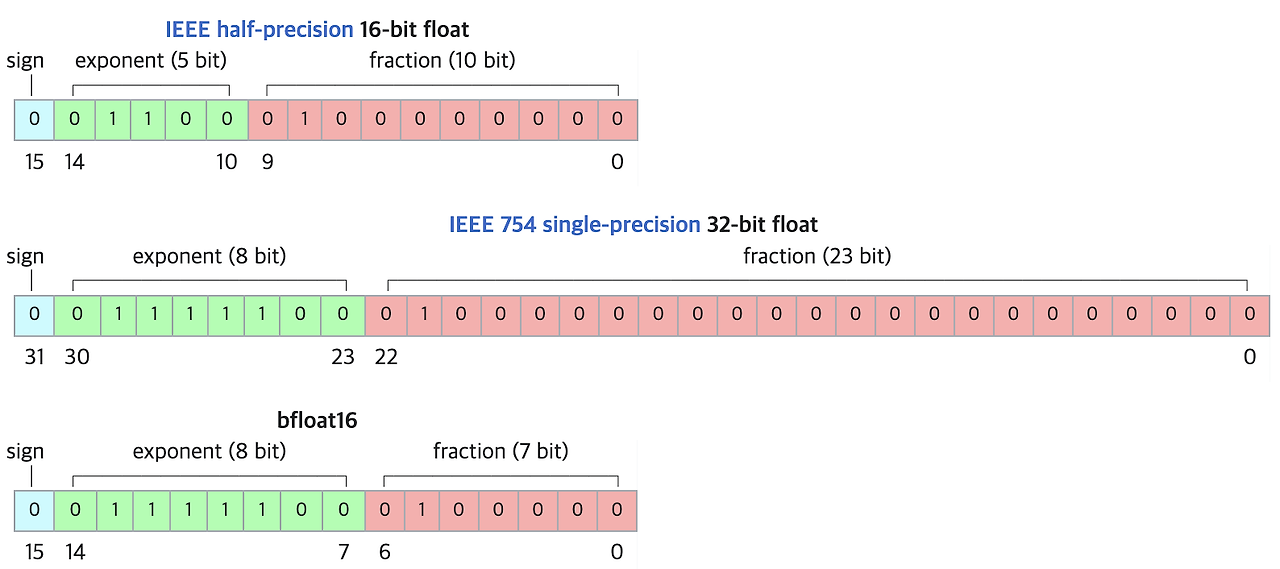

- float16: 지수 5비트, 가수 10비트
  - 표현 범위가 좁지만 같은 범위 안에서 bfloat16보다 정밀
  - 매우 큰 값이나 작은 값은 범위를 벗어날 가능성이 높음
- bfloat16: 지수 8비트, 가수 7비트
  - float32와 같은 크기의 지수부를 사용해 표현 범위가 넓음
  - 표현 범위가 넓은 대신 float16보다 정밀도가 낮음
- 공통점: 파라미터당 2바이트로 float32의 절반만 사용
- 실습 환경: EXAONE의 원본 파라미터는 bfloat16이지만 T4 GPU에서는 float16으로 변환하여 사용

In [13]:
token_ids = tokenizer("언어 모형은 다음 토큰을 예측한다.")["input_ids"]
len(token_ids)  # 토큰 수

9

### 같은 입력으로 비교
- 비교 원칙: 디코딩 방법만 바꾸고 모형, 입력, 최대 생성 길이는 고정
- 입력 문장: 설명문의 뒷부분을 이어 쓰는 일반 문자열

In [14]:
prompt = "인공지능은 데이터를 학습하여 패턴을 찾는다. 이를 활용하면"  # 공통 입력
inputs = tokenizer(
    prompt,
    return_tensors="pt",  # 토큰 ID를 PyTorch 텐서로 반환
).to(model.device)         # 입력을 모형과 같은 장치로 이동

input_length = inputs["input_ids"].shape[1]  # 입력 토큰 수
inputs["input_ids"].shape  # 배치 크기와 입력 토큰 수

torch.Size([1, 16])

- 입력 변환 결과: 일반 문자열이 16개 토큰으로 변환

- decode_new_tokens(): 입력 이후에 새로 생성한 부분만 문자열로 복원

In [15]:
def decode_new_tokens(output_ids):
    return tokenizer.batch_decode(
        output_ids[:, input_length:],  # 입력을 제외한 생성 토큰만 선택
        skip_special_tokens=True,      # 제어용 특수 토큰은 문자열에서 제외
    )

### 언어 모형의 탐욕 탐색
- do_sample=False: 확률에 따른 무작위 추출을 사용하지 않음
- num_beams=1: 매 단계에서 후보 하나만 유지

In [16]:
with torch.inference_mode():  # 기울기 계산을 꺼 메모리와 연산 절약
    greedy_ids = model.generate(
        **inputs,           # input_ids와 attention_mask 전달
        max_new_tokens=48,  # 입력 뒤에 최대 48개 토큰 생성
        do_sample=False,    # 확률에 따른 무작위 추출을 끔
        num_beams=1,        # 후보 하나만 유지하는 탐욕 탐색
        use_cache=True,     # 이전 토큰의 Key·Value를 KV 캐시에 저장해 재사용
    )

greedy_text = decode_new_tokens(greedy_ids)[0]  # 첫 번째 생성 문장
greedy_text  # 탐욕 탐색 결과

' 더 이상의 시간이 있는 것으로 알 수 있다.'

- 생성 결과: 짧은 한 문장을 생성했지만 입력 의미와의 연결은 약함
- 결과의 의미: 매 단계에서 가장 높은 확률의 토큰을 선택했지만 문장 전체의 최적해라는 보장은 없음

### 빔 탐색
- 빔 탐색(beam search): 매 단계에서 확률이 높은 문장 후보를 여러 개 유지
- 빔 크기(beam size): 유지할 후보 수
  - num_beams=4: 후보 네 개를 유지하며 확장
- num_return_sequences=3: 최종 후보 중 세 개를 반환
- 탐욕 탐색과의 관계: num_beams=1인 빔 탐색은 탐욕 탐색과 같음
- 가상 언어 모형에 빔 크기 2를 적용:
  - 첫 단계: 나는(0.6)과 오늘(0.4)을 모두 유지
  - 둘째 단계: 네 후보 중 전체 확률이 높은 오늘 걷는다(0.36)와 나는 걷는다(0.33)를 유지
  - 최종 선택: 탐욕 탐색이 놓친 오늘 걷는다
- 한계: 빔 크기를 넘는 후보는 버리므로 전체 확률이 가장 높은 문장을 항상 찾지는 못함

In [17]:
with torch.inference_mode():  # 기울기 계산을 끔
    beam_ids = model.generate(
        **inputs,                 # 토큰화한 입력 전달
        max_new_tokens=48,        # 새 토큰을 최대 48개 생성
        do_sample=False,          # 무작위 추출을 사용하지 않음
        num_beams=4,              # 매 단계에서 후보 네 개 유지
        num_return_sequences=3,   # 최종 후보 세 개 반환
        early_stopping=True,      # 완성된 후보가 충분하면 탐색 종료
        use_cache=True,           # 이전 토큰의 Key·Value를 KV 캐시에 저장해 재사용
    )

beam_texts = decode_new_tokens(beam_ids)
for text in beam_texts:  # 반환된 후보를 차례로 출력
    print(text)

 원하는 가치를 선택할 수 있다. 원하는 가치를 선택하는 것은 다른 사람들과 비교하는 것과 같다. 다른 사람들과 비교하는 것도 가능하다. 다른 사람들과 비교
 원하는 가치를 선택할 수 있다. 원하는 가치를 선택하는 것은 다른 사람들과 비교하는 것과 같다. 다른 사람들과 비교하는 것도 가능하다. 다른 사람들과의
 원하는 가치를 선택할 수 있다. 원하는 가치를 선택하는 것은 다른 사람들과 비교하는 것과 같다. 다른 사람들과 비교하는 것은 다른 사람들과 같은 정도로


- 탐욕 탐색과의 차이: 첫 토큰부터 다른 문장을 생성
  - 가상 언어 모형의 예처럼 첫 단계에서 확률이 가장 높지 않은 토큰으로 시작한 문장이 전체 점수는 더 높았음
- 후보 사이의 차이: 세 후보가 거의 같은 문장 구조와 표현을 사용
- 최대 생성 길이: 세 후보 모두 문장을 끝내지 못한 채 생성이 종료
- 주의: 빔 수를 늘려도 사람이 보기에 더 좋은 문장이 반드시 생성되는 것은 아님

### 다양한 빔 탐색
- 일반 빔 탐색의 문제: 점수가 높은 후보들이 같은 시작과 문장 구조에 몰리기 쉬움
- 다양한 빔 탐색(Diverse Beam Search): 빔을 여러 그룹으로 나누고 비슷한 선택에 벌점을 적용

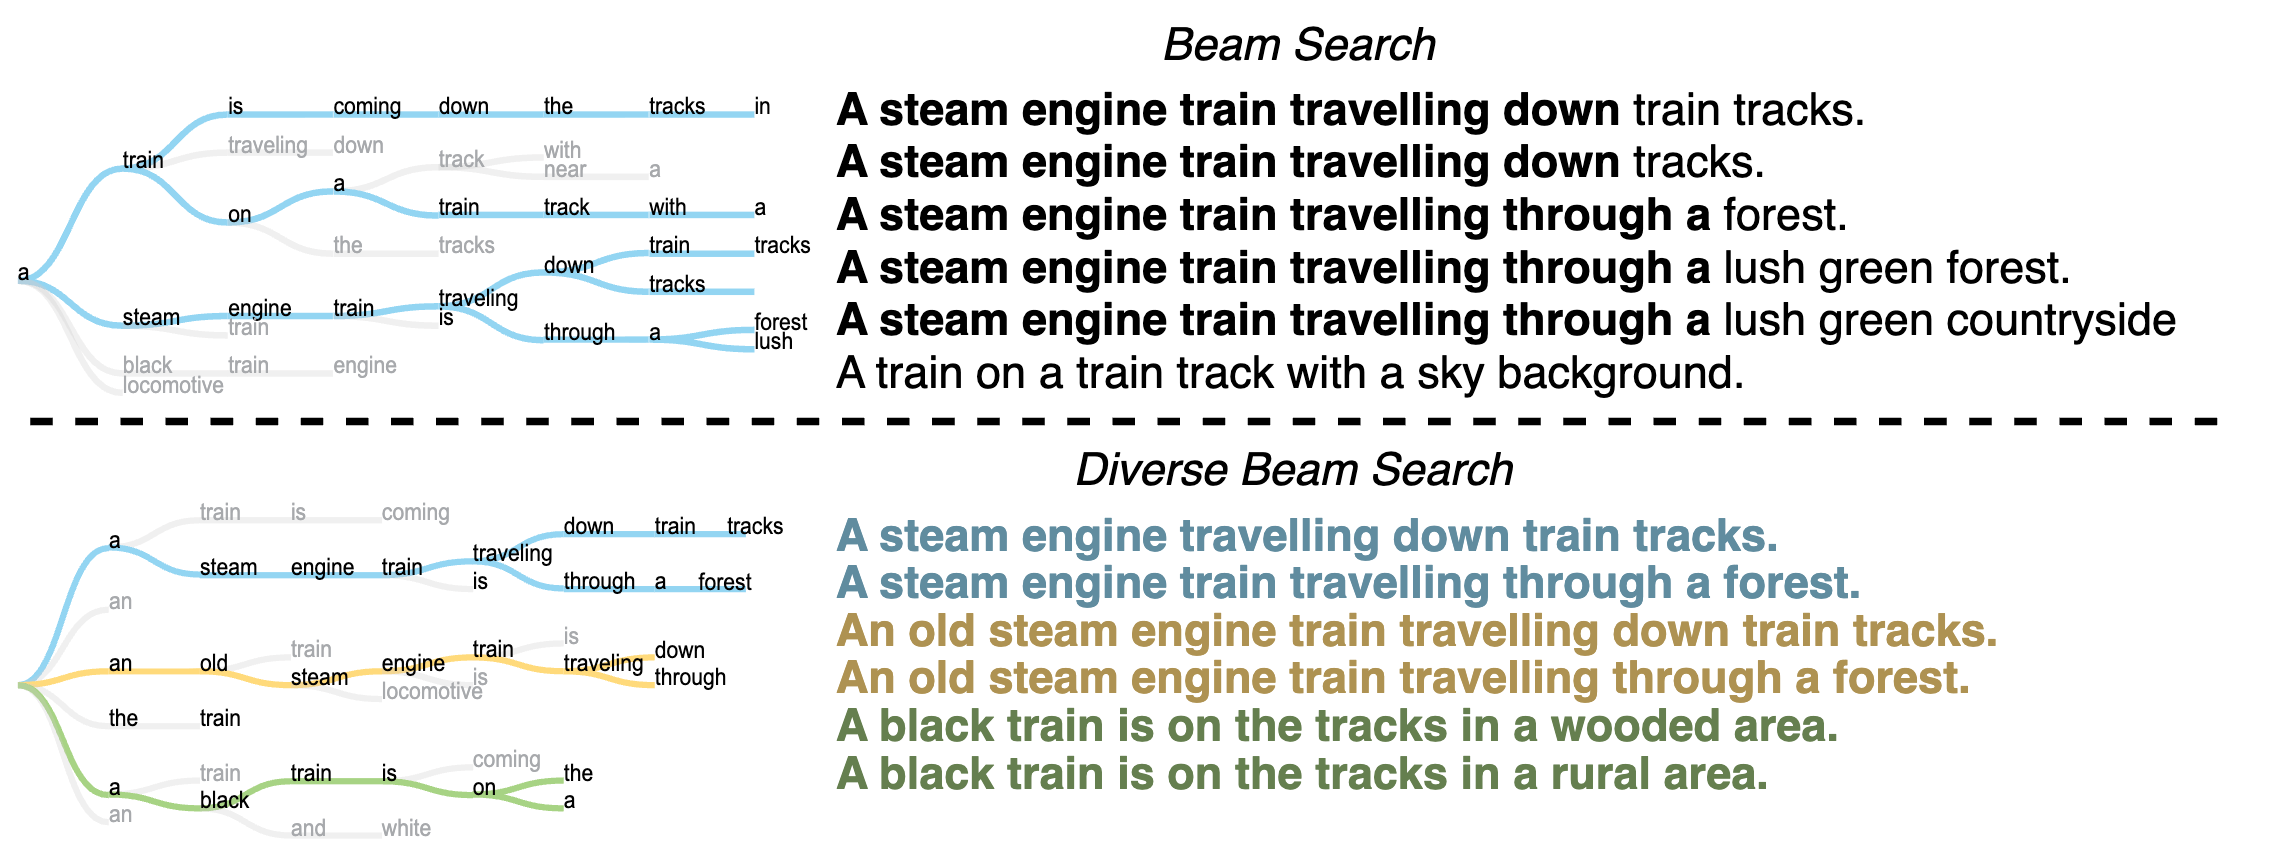

- 위 그림: 기차 사진의 설명문을 생성한 예
  - 일반 빔 탐색(위): 여섯 후보 중 다섯이 A steam engine train travelling으로 시작
  - 다양한 빔 탐색(아래): 세 그룹이 A steam engine, An old steam engine, A black train으로 서로 다르게 시작

- 그룹별 탐색:
  - 첫 번째 그룹: 일반 빔 탐색처럼 점수가 높은 후보를 선택
  - 다음 그룹: 같은 생성 단계에서 앞선 그룹이 선택한 토큰의 점수를 낮춘 뒤 후보를 선택
  - 각 그룹: 선택한 후보를 다음 단계까지 따로 유지해 서로 다른 문장 경로를 탐색

In [18]:
with torch.inference_mode():  # 기울기 계산을 끔
    diverse_beam_ids = model.generate(
        **inputs,                 # 토큰화한 입력 전달
        max_new_tokens=48,        # 새 토큰을 최대 48개 생성
        do_sample=False,          # 무작위 추출을 사용하지 않음
        num_beams=6,              # 전체 후보 여섯 개 유지
        num_beam_groups=3,        # 후보를 세 그룹으로 분할
        diversity_penalty=2.0,    # 앞선 그룹과 같은 선택에 벌점 적용
        num_return_sequences=3,   # 최종 후보 세 개 반환
        use_cache=True,           # 이전 토큰의 Key·Value를 KV 캐시에 저장해 재사용
    )

diverse_beam_texts = decode_new_tokens(diverse_beam_ids)
for text in diverse_beam_texts:  # 반환된 후보를 차례로 출력
    print(text)

Group Beam Search is scheduled to be moved to a `custom_generate` repository in v4.55.0. To prevent loss of backward compatibility, add `trust_remote_code=True` to your `generate` call.


 원하는 가치를 선택할 수 있다. 원하는 가치를 선택하는 것은 다른 사람들과 비교하는 것과 같다. 다른 사람들과 비교하는 것도 가능하다. 다른 사람들과 비교
 원하는 가치를 선택할 수 있다. 원하는 가치를 선택하는 것은 다른 사람들과 비교하는 것과 같다. 다른 사람들과 비교하는 것도 가능하다. 다른 사람들과의
 추가 비용이 발생할 수 있다. 필요하며, 필요하며.


- 일반 빔 탐색과의 공통점: 앞의 두 후보는 같은 결과
- 다양한 빔 탐색의 차이: 세 번째 후보가 다른 시작과 내용을 사용
- 한계: 후보 사이의 차이를 강제로 키우면 문맥 적합성이나 문장 품질이 낮아질 수 있음

### 대조 탐색
- 대조 탐색(contrastive search): 확률이 높은 후보 중에서 이전 표현과 지나치게 비슷하지 않은 토큰을 선택
- 후보: 현재 단계에서 확률이 높은 상위 k개 토큰
- 후보 점수: 두 기준을 하나로 합쳐 점수가 가장 높은 후보를 선택
  - 점수=(1−α)×확률−α×최대 유사도
- 확률: 현재 문맥 다음에 그 토큰이 올 확률
  - 모형이 자연스럽다고 보는 토큰에 높은 점수
- 최대 유사도: 후보 토큰의 표현을 앞에서 생성한 토큰들의 표현과 비교했을 때 가장 비슷한 정도
  - 이미 나온 표현과 비슷할수록 큰 값을 빼므로 반복이 억제됨
- α: 두 기준의 비중을 정하는 0과 1 사이의 값
  - α=0: 확률만 비교하므로 탐욕 탐색과 같음
  - α가 커질수록 반복에 더 강한 벌점 적용

In [19]:
with torch.inference_mode():  # 기울기 계산을 끔
    contrastive_ids = model.generate(
        **inputs,            # 토큰화한 입력 전달
        max_new_tokens=48,   # 새 토큰을 최대 48개 생성
        do_sample=False,     # 무작위 추출을 사용하지 않음
        penalty_alpha=0.6,   # 반복 억제와 모형 확률의 균형 조절
        top_k=4,             # 확률이 높은 토큰 네 개를 비교
        use_cache=True,      # 이전 토큰의 Key·Value를 KV 캐시에 저장해 재사용
    )

contrastive_text = decode_new_tokens(contrastive_ids)[0]  # 첫 번째 생성 문장
contrastive_text  # 대조 탐색 결과

Contrastive Search is scheduled to be moved to a `custom_generate` repository in v4.55.0. To prevent loss of backward compatibility, add `trust_remote_code=True` to your `generate` call.


' 원하는 가치를 쉽게 구할 수 있다.'

- 생성 결과: 빔 탐색보다 짧고 반복이 적은 문장을 생성
- 해석: 확률뿐 아니라 앞선 토큰 표현과의 유사성도 선택 기준에 포함해 다른 결과를 생성
- 주의: 한 예의 결과만으로 특정 방법이 항상 더 좋다고 판단할 수 없음

| 방법 | 단계마다 유지하는 후보 | 특징 | 주요 한계 |
|---|---|---|---|
| 완전 탐색 | 모든 후보 | 전체 후보 중 최고 점수 확인 | 후보 수가 지수적으로 증가 |
| 탐욕 탐색 | 1개 | 가장 빠르고 단순 | 초기에 버린 후보를 복구할 수 없음 |
| 빔 탐색 | 여러 개 | 문장 후보를 병렬로 비교 | 후보가 서로 비슷해지기 쉬움 |
| 다양한 빔 탐색 | 여러 그룹 | 후보 사이의 차이를 유도 | 다양성과 품질 사이의 조절 필요 |
| 대조 탐색 | 1개 (상위 *k*개 토큰을 비교해 선택) | 확률과 반복 억제를 함께 고려 | 추가 계산과 매개변수 설정 필요 |
|

- 공통점: 확률에 따른 무작위 추출을 사용하지 않음
- 차이점: 탐색 범위와 후보를 평가하는 기준
- 실무 선택: 정답이 하나가 아니라면 최고 확률만 추구하기보다 과업의 목적과 생성 품질을 함께 평가

### 비교할 입력
- 비교 조건: 탐욕 탐색으로 새 토큰을 64개씩 생성하고 KV 캐시 사용 여부만 변경

In [20]:
prompt = "인공지능은 데이터를 학습하여 패턴을 찾는다. 이를 활용하면"  # 공통 입력
inputs = tokenizer(
    prompt,
    return_tensors="pt",  # 토큰 ID를 PyTorch 텐서로 반환
).to(model.device)         # 입력을 모형과 같은 장치로 이동

### 시간 측정
- perf_counter(): 코드 실행 시간 측정용 타이머
- torch.cuda.synchronize(): 예약된 GPU 연산이 끝날 때까지 기다림
  - GPU 연산은 비동기로 실행되므로 측정 시작과 종료 직전에 호출

In [21]:
from time import perf_counter


def measure_generation(use_cache, new_tokens):
    if torch.cuda.is_available():
        torch.cuda.synchronize()  # 이전 GPU 연산이 끝난 뒤 측정 시작

    start = perf_counter()
    with torch.inference_mode():  # 기울기 계산을 끄고 생성 시간만 측정
        output_ids = model.generate(
            **inputs,                    # 같은 입력 사용
            min_new_tokens=new_tokens,   # 종료 토큰이 나와도 정한 길이까지 생성
            max_new_tokens=new_tokens,   # 캐시 조건별 생성 길이 고정
            do_sample=False,             # 탐욕 탐색 사용
            num_beams=1,                 # 문장 후보 하나만 유지
            use_cache=use_cache,         # KV 캐시 사용 여부
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()  # 예약된 GPU 연산이 끝난 뒤 측정 종료

    elapsed_seconds = perf_counter() - start
    return output_ids, elapsed_seconds

### 캐시를 켜고 끄기
- 워밍업(warm-up): 연산 초기화 시간을 측정에서 제외하기 위한 짧은 사전 실행

In [22]:
_ = measure_generation(use_cache=False, new_tokens=4)  # 캐시를 끈 워밍업
_ = measure_generation(use_cache=True, new_tokens=4)   # 캐시를 켠 워밍업

uncached_ids, uncached_seconds = measure_generation(
    use_cache=False,
    new_tokens=64,
)
cached_ids, cached_seconds = measure_generation(
    use_cache=True,
    new_tokens=64,
)

In [23]:
uncached_seconds  # 캐시를 끈 생성 시간(초)

6.298155790000237

In [24]:
cached_seconds  # 캐시를 켠 생성 시간(초)

3.130221254999924

In [25]:
uncached_seconds / cached_seconds  # 시간 비율(끔/켬)

2.012048119582649

- 실행 결과:
  - 캐시를 끈 경우: 약 6.25초
  - 캐시를 켠 경우: 약 3.13초
  - 시간 비율: 캐시를 켠 쪽이 약 2배 빠른 결과
- 차이가 크지 않은 이유: 입력 16개, 생성 64개 토큰으로 문맥이 짧아 다시 계산하는 양이 적음
  - 입력이나 생성이 길어질수록 캐시를 껐을 때 다시 계산하는 양이 늘어 차이가 커짐

### 생성 결과 비교
- 캐시의 역할: 중복 계산을 줄이는 최적화
- 토큰 선택 규칙: KV 캐시 사용 여부와 무관

In [26]:
torch.equal(uncached_ids, cached_ids)  # 생성 토큰 일치 여부

True

- 생성 토큰: 두 조건에서 모두 일치
- 해석: KV 캐시는 탐욕 탐색의 선택 규칙을 바꾸지 않고 생성의 반복 계산을 줄임

### 확률적 디코딩
- 확률적 디코딩(stochastic decoding): 다음 토큰의 확률분포에서 토큰을 무작위로 추출하는 방법
- 필요한 이유: 결정론적 디코딩은 같은 입력에 항상 같은 답을 내고 반복이 잦음
  - 대화, 창작처럼 다양한 답이 필요한 과업에서는 무작위 추출이 유리
- do_sample=True: Transformers에서 확률에 따른 무작위 추출을 사용
- 특징: 같은 입력과 설정에서도 실행할 때마다 다른 결과가 나올 수 있음
- 난수 시드(random seed): 무작위 추출 순서를 고정해 결과를 비교할 때 사용

### 온도
- 온도(temperature): 토큰 사이의 확률 차이를 조절하는 양수
- T=1: 원래 확률분포를 유지
- 0<T<1: 확률이 높은 토큰에 더 집중
  - T가 0에 가까워지면 최고 확률 토큰만 남아 탐욕 탐색과 비슷해짐
- T>1: 확률 차이를 줄여 다양한 토큰을 선택할 가능성을 높임
- 소프트맥스(softmax): 모형의 점수를 확률로 바꾸는 함수
  - 온도: 점수를 T로 나눈 뒤 소프트맥스를 적용
  
    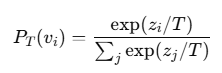
- z
i
​
 : 토큰 v
i
​
 에 대한 모형의 점수
 - 간단한 비교: 세 토큰의 점수를 각각 2, 1, 0으로 가정

In [27]:
logits = torch.tensor([2.0, 1.0, 0.0])  # 세 토큰의 가상 점수

for temperature in [0.7, 1.0, 1.3]:
    probabilities = torch.softmax(
        logits / temperature,
        dim=-1,  # 토큰 차원의 점수를 확률로 변환
    )
    print(temperature, probabilities)

0.7 tensor([0.7710, 0.1848, 0.0443])
1.0 tensor([0.6652, 0.2447, 0.0900])
1.3 tensor([0.5959, 0.2761, 0.1280])


- 낮은 온도: 첫 토큰의 확률이 0.7710으로 증가
- 높은 온도: 세 토큰의 확률 차이가 감소

### 같은 입력으로 비교
- 비교 원칙: 일반 문자열과 최대 생성 길이를 고정하고 디코딩 설정만 변경

In [28]:
prompt = "인공지능은 데이터를 학습하여 패턴을 찾는다. 이를 활용하면"  # 공통 입력
inputs = tokenizer(
    prompt,
    return_tensors="pt",  # 토큰 ID를 PyTorch 텐서로 반환
).to(model.device)         # 입력을 모형과 같은 장치로 이동

input_length = inputs["input_ids"].shape[1]  # 입력 토큰 수
inputs["input_ids"].shape  # 배치 크기와 입력 토큰 수

torch.Size([1, 16])

- sample_text(): 난수 시드와 디코딩 설정을 받아 새로 생성한 부분만 복원

In [29]:
def sample_text(seed, **decoding_args):  # 디코딩 설정을 키워드 인자로 받음
    torch.manual_seed(seed)  # 반복 비교를 위해 난수 시드 고정
    with torch.inference_mode():  # 기울기 계산을 꺼 메모리와 연산 절약
        output_ids = model.generate(
            **inputs,           # input_ids와 attention_mask 전달
            max_new_tokens=24,  # 입력 뒤에 최대 24개 토큰 생성
            do_sample=True,     # 확률분포에서 다음 토큰을 추출
            use_cache=True,     # 이전 토큰의 Key·Value를 KV 캐시에 저장해 재사용
            **decoding_args,    # temperature, top_k, top_p 등을 전달
        )
    return tokenizer.decode(
        output_ids[0, input_length:],  # 첫 결과에서 입력을 제외한 토큰만 선택
        skip_special_tokens=True,     # 제어용 특수 토큰은 문자열에서 제외
    )

### 온도에 따른 생성
- 비교 조건: 난수 시드, top-k, top-p를 고정하고 온도만 변경

In [30]:
for temperature in [0.7, 1.0, 1.3]:
    text = sample_text(
        seed=5,                  # 동일한 난수 순서로 비교
        temperature=temperature,  # 현재 반복의 온도
        top_k=50,                # 상위 50개 토큰만 후보로 유지
        top_p=1.0,               # 누적 확률에 따른 후보 제한은 끄기
    )
    print(temperature, text)

0.7  데이터가 쌓이는 효과가 있다.
1.0  이상이 정의된다. 따라서 이상이라는 단어와 같은 이론을 찾을 수도 있다. 이를 정리
1.3  이상이 정의된다. 따라서 이상 분석 결과와 같이 이상을 유추할 값이 있다. 결론 페이지 채널


- 온도 변화: 같은 난수를 사용해도 서로 다른 토큰을 선택
- 온도 1.0의 결과: 한국어 문장에 영어 토큰 emerges가 섞임
  - 무작위 추출에서는 확률이 높지 않은 토큰도 뽑힐 수 있음을 보여 줌
- 생성 품질: 온도가 높거나 낮다는 사실만으로 결정되지 않음

### Top-k 추출
- Top-k 추출: 확률이 높은 k개 토큰만 남기고 그 안에서 다음 토큰을 추출
- 작은 k: 확률이 높은 소수의 토큰에 집중
- 큰 k: 선택 범위가 넓어지지만 낮은 확률의 토큰도 포함될 수 있음

In [31]:
for top_k in [5, 20, 50]:
    text = sample_text(
        seed=1,            # 동일한 난수 순서로 비교
        temperature=1.0,  # 원래 확률분포 유지
        top_k=top_k,       # 현재 반복의 후보 개수
        top_p=1.0,         # 누적 확률에 따른 후보 제한은 끄기
    )
    print(top_k, text)

5  원하는 만큼 쉽게 원하는 만큼 쉽게 원하는 만큼 더 좋은 추가가 있다.
20  됩니다. 이와 같은 지식도 데이터로 볼 수 있습니다. 등과 같은 의미도 동일하며
50  됩니다. 이 자체가 논리적으로 생각하는 배경이 있는 시점이 있는 그러한 영역이 있는


- top_k=5: 가장 높은 확률의 토큰 다섯 개 안에서만 선택
- k의 증가: 후보가 늘어나며 생성 결과도 달라짐
- 최대 생성 길이: 두 번째 결과는 문장을 끝내기 전에 24개 토큰에 도달

### Top-p 추출
- Top-p 추출: 확률이 높은 순서로 토큰을 모아 누적 확률이 p 이상이 되는 최소 후보 집합에서 추출
- 핵 추출(nucleus sampling): Top-p 추출의 다른 이름
- 후보 수: 각 단계의 확률분포에 따라 달라짐
  - 확신이 높은 분포에서는 적은 토큰만 선택
  - 확률이 고른 분포에서는 많은 토큰을 선택
- top_k=0: top-k 제한을 끄고 top-p의 효과만 비교

In [32]:
for top_p in [0.7, 0.9, 0.95]:
    text = sample_text(
        seed=5,            # 동일한 난수 순서로 비교
        temperature=1.0,  # 원래 확률분포 유지
        top_k=0,           # top-k 후보 제한은 끄기
        top_p=top_p,       # 현재 반복의 누적 확률 기준
    )
    print(top_p, text)

0.7  이상이 정의된다. 따라서 이상이라는 단어가 정리되어 사용 가능한 가치를 계산하는 데
0.9  이상자기 분류가 가능하다고 할 수 있다.
0.95  이상자기 분류가 가능하다고 할 수 있음. 급수 부분 급 호 호 호 호 호 호 호 호 호


- 낮은 p: 확률이 높은 소수의 후보에 집중
- 높은 p: 후보 범위가 넓어져 예상하기 어려운 표현이 포함될 수 있음

### 온도와 후보 제한 조합
- 실제 생성: 온도, top-k, top-p를 함께 사용하는 경우가 많음
- 아래 설정: 온도를 조금 낮추고 낮은 확률의 꼬리 부분을 제한
- 비교 조건: 디코딩 설정은 고정하고 난수 시드만 변경

In [33]:
for seed in [3, 6, 9]:
    text = sample_text(
        seed=seed,        # 현재 반복의 난수 시드
        temperature=0.8,  # 상위 확률 토큰에 조금 더 집중
        top_k=50,         # 상위 50개 토큰만 후보로 유지
        top_p=0.9,        # 누적 확률 0.9에 도달하는 최소 후보만 유지
    )
    print(seed, text)

3  학습하는 내용을 추가하는 효과가 있다.
6  이상이가가가가가가가가가가가가가가가나나 이상이가가가
9  원하는 시간대에 대해 원하고 있다는 사실을 확인할 수 있다는 점에서 다른 사람들과 비교가


- 같은 설정: 난수 시드에 따라 서로 다른 문장을 생성
- 매개변수 선택: 다양성뿐 아니라 문맥 적합성, 반복, 문법도 함께 확인

### 방법 비교
| 방법 | 후보를 정하는 기준 | 값을 높이면 |
|---|---|---|
| 온도 | 전체 확률분포의 평탄한 정도 | 낮은 확률의 토큰을 선택할 가능성 증가 |
| Top-k | 확률이 높은 토큰의 개수 | 후보 수 증가 |
| Top-p | 후보의 누적 확률 | 후보 수가 대체로 증가 |

- 공통점: do_sample=True에서 확률에 따라 다음 토큰을 추출
- 차이점: 온도는 확률분포를 바꾸고, top-k와 top-p는 추출할 후보를 제한